# MI:EMSE 70:30 Follow-up

Three new missions and 15 verified earlier missions.

This is an exploratory follow-up requested after viewing the earlier five-policy comparison. Only three new 70:30 missions were executed, at the unchanged mission starts 72, 80 and 88 hours. The 15 earlier missions, three history-only controls, public acquisition catalogs, travel matrices, reference records and numerical checks are reused byte-for-byte and their hashes are verified. Existing run directories, reports and result pointers remain intact.

The new objective is `0.7 * MI / s_MI + 0.3 * EMSE_reduction / s_EMSE`. The unchanged normalizers were fixed from initial single-event gains within each window. Saved scores independently verify that every selected route uses MI weight 0.7 and EMSE weight 0.3. There is no new kernel training or change to the GP checkpoint, GRG depth 2, candidate nodes, synthetic map, navigation, 0.35 m/s speed, 5 s dwell or 900 s budget. Computation remains outside the original simulated mission clock; measured wall times are recorded separately.

Reconstruction uses the same latest held-out actual record per reachable sensor in the last five minutes before the mission deadline. This is retrospective reconstruction at recorded locations, not dense measured map truth or a held-out-sensor test. Forecasts freeze the final GP at the same common deadline and evaluate strictly later held-out records in (0,15], (15,30] and (30,60] minutes, with no future conditioning. EMSE still targets the deadline field; future forecasting is an additional evaluation, not a changed planning objective.

Primary summary values are arithmetic means of the three window RMSEs, in C; lower is better. MAE, sensor-balanced RMSE and predictive coverage are also saved in the aggregate CSV; per-window metric JSONs additionally include NLPD. The three windows are correlated portions of one dataset. Adding 70:30 after inspecting the earlier results is exploratory tuning on the same evaluation windows, not independent validation of a best ratio. Any selected ratio still needs a separate-day or separate-field test.


In [1]:
from pathlib import Path
import csv, hashlib, json
import numpy as np
from IPython.display import display, Image, Markdown
root = Path.cwd()
run = root / '11.2_result/strict_plus_70_30_20261103T025338Z'
read = lambda p: json.loads(p.read_text())
assert read(run/'verification.json')['passed']
assert read(run/'extension_verification.json')['passed']
for relative,digest in read(run/'artifacts_sha256.json').items():
    assert hashlib.sha256((run/relative).read_bytes()).hexdigest()==digest,relative
print('Pinned extension:',run.name)
print('Newly executed missions:',read(run/'extension_verification.json')['newly_executed_missions'])
print('Requested weights:',read(run/'config_frozen.json')['weights_mi_emse']['fusion_70_30'])
print('Artifact and causal checks passed.')

Pinned extension: strict_plus_70_30_20261103T025338Z
Newly executed missions: 3
Requested weights: [0.7, 0.3]
Artifact and causal checks passed.


## Mean of the three window RMSEs

| Policy (MI:EMSE) | Reconstruction | Forecast (0,15] min | Forecast (15,30] min | Forecast (30,60] min |
|---|---:|---:|---:|---:|
| History only | 5.137181 | 5.474390 | 5.240287 | 5.239110 |
| MI | 1.239073 | 1.395163 | 1.860237 | 1.953275 |
| EMSE | 1.152650 | 1.353696 | 1.896846 | 1.993748 |
| MI:EMSE 50:50 | 1.355537 | 1.573829 | 2.063748 | 2.149030 |
| MI:EMSE 40:60 | 1.355537 | 1.573829 | 2.063748 | 2.149030 |
| MI:EMSE 60:40 | 1.217038 | 1.343509 | 1.824843 | 1.873229 |
| MI:EMSE 70:30 | 1.378565 | 1.496170 | 2.012189 | 2.085897 |

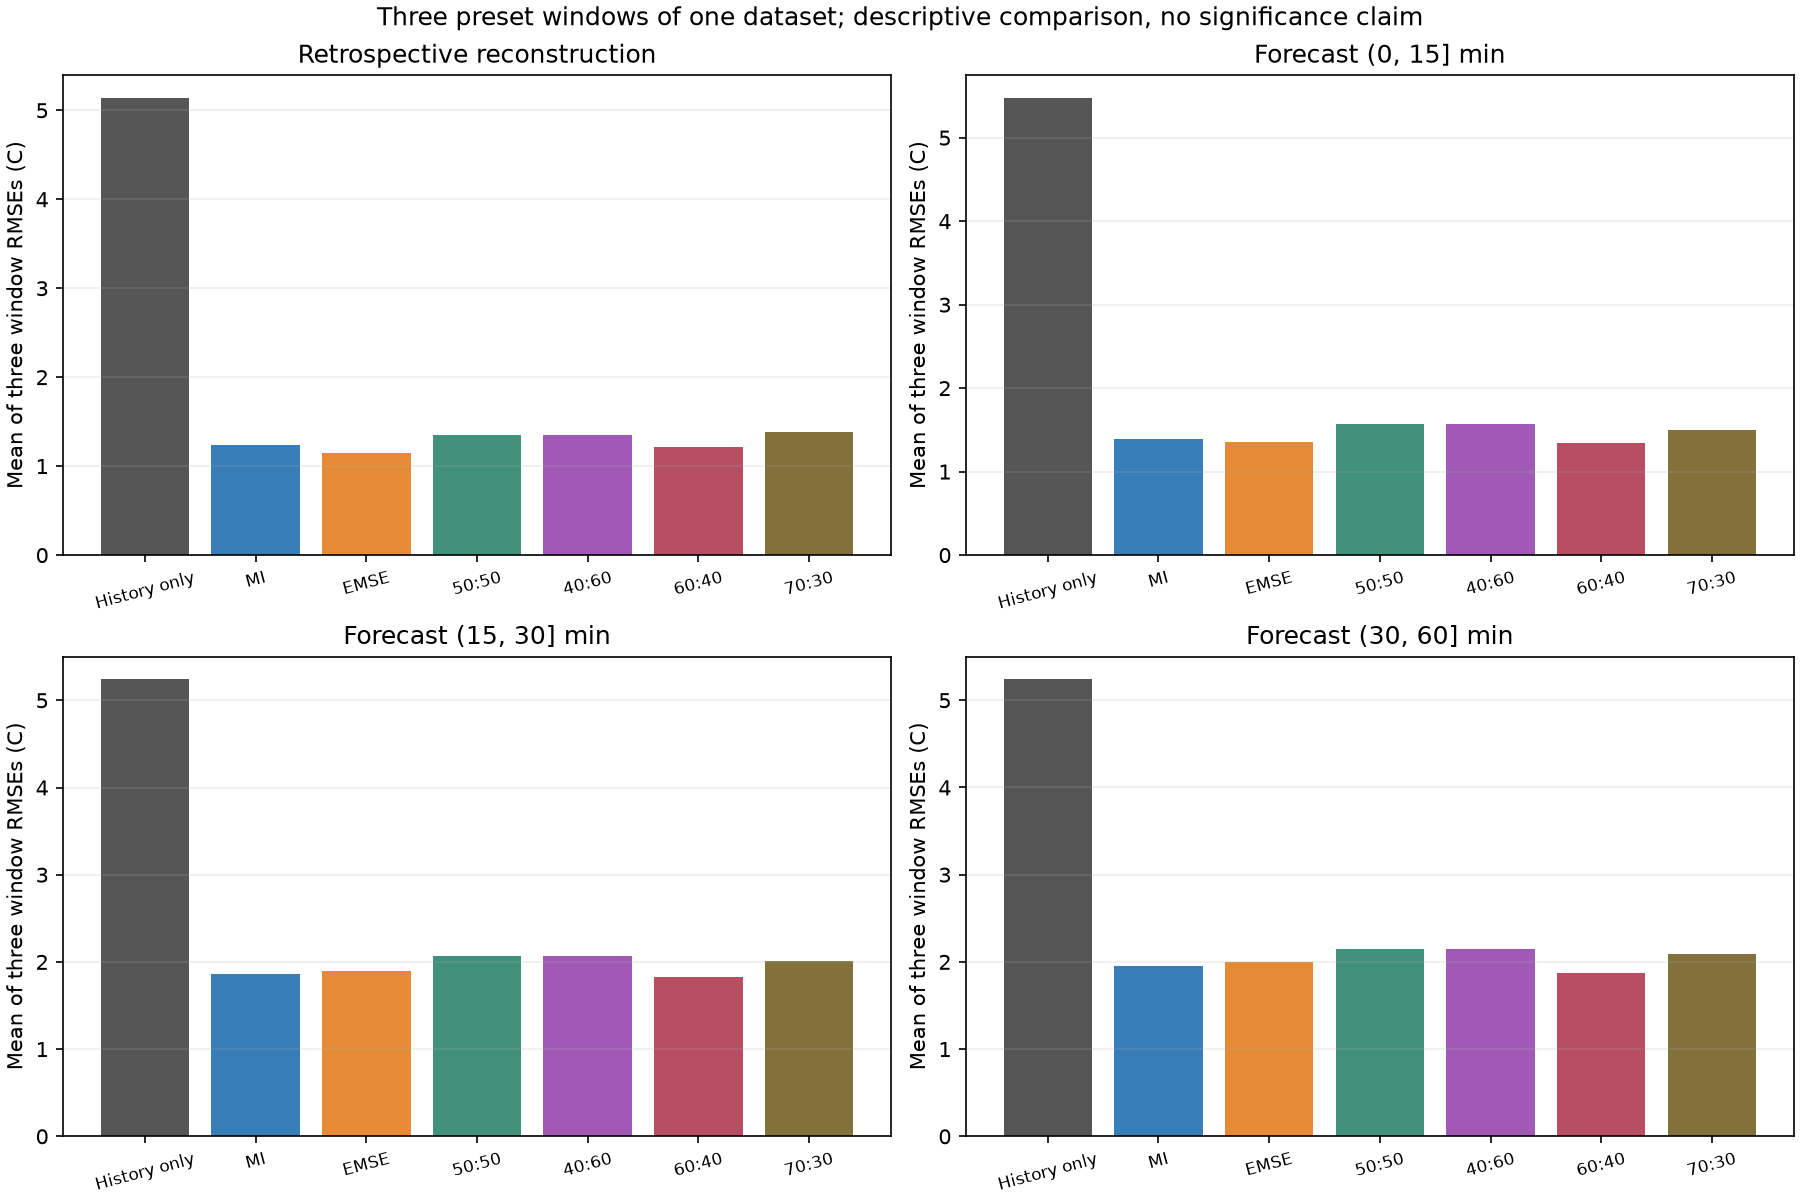

In [2]:
display(Markdown('| Policy (MI:EMSE) | Reconstruction | Forecast (0,15] min | Forecast (15,30] min | Forecast (30,60] min |\n|---|---:|---:|---:|---:|\n| History only | 5.137181 | 5.474390 | 5.240287 | 5.239110 |\n| MI | 1.239073 | 1.395163 | 1.860237 | 1.953275 |\n| EMSE | 1.152650 | 1.353696 | 1.896846 | 1.993748 |\n| MI:EMSE 50:50 | 1.355537 | 1.573829 | 2.063748 | 2.149030 |\n| MI:EMSE 40:60 | 1.355537 | 1.573829 | 2.063748 | 2.149030 |\n| MI:EMSE 60:40 | 1.217038 | 1.343509 | 1.824843 | 1.873229 |\n| MI:EMSE 70:30 | 1.378565 | 1.496170 | 2.012189 | 2.085897 |'))
display(Image(filename=str(run/'figures/strict_comparison.png')))

## 70:30 versus 60:40

- Retrospective reconstruction: 70:30 = 1.378565 C, 60:40 = 1.217038 C; difference = +0.161527 C (negative favors 70:30).
- Forecast (0, 15] min: 70:30 = 1.496170 C, 60:40 = 1.343509 C; difference = +0.152661 C (negative favors 70:30).
- Forecast (15, 30] min: 70:30 = 2.012189 C, 60:40 = 1.824843 C; difference = +0.187347 C (negative favors 70:30).
- Forecast (30, 60] min: 70:30 = 2.085897 C, 60:40 = 1.873229 C; difference = +0.212669 C (negative favors 70:30).

- w00: 70:30 acquired the identical ordered record sequence as MI:EMSE 50:50, MI:EMSE 40:60, MI:EMSE 60:40.
- w08: 70:30 acquired the identical ordered record sequence as MI, MI:EMSE 60:40.
- w16: 70:30 acquired a different ordered record sequence from all earlier arms.

| Window | Policy | Reconstruction RMSE | Forecast (0,15] | Forecast (15,30] | Forecast (30,60] |
|---|---|---:|---:|---:|---:|
| w00 | History only | 0.489578 | 0.463602 | 0.473355 | 0.463175 |
| w00 | MI | 0.546907 | 0.567876 | 0.578728 | 0.614442 |
| w00 | EMSE | 0.527523 | 0.486340 | 0.543291 | 0.627064 |
| w00 | MI:EMSE 50:50 | 0.496601 | 0.501875 | 0.513260 | 0.529163 |
| w00 | MI:EMSE 40:60 | 0.496601 | 0.501875 | 0.513260 | 0.529163 |
| w00 | MI:EMSE 60:40 | 0.496601 | 0.501875 | 0.513260 | 0.529163 |
| w00 | MI:EMSE 70:30 | 0.496601 | 0.501875 | 0.513260 | 0.529163 |
| w08 | History only | 7.644961 | 8.111826 | 7.824759 | 7.767400 |
| w08 | MI | 1.242893 | 1.351817 | 2.773157 | 3.061642 |
| w08 | EMSE | 0.989282 | 1.305019 | 2.855750 | 3.158509 |
| w08 | MI:EMSE 50:50 | 1.194340 | 1.348177 | 2.882170 | 3.168412 |
| w08 | MI:EMSE 40:60 | 1.194340 | 1.348177 | 2.882170 | 3.168412 |
| w08 | MI:EMSE 60:40 | 1.242893 | 1.351817 | 2.773157 | 3.061642 |
| w08 | MI:EMSE 70:30 | 1.242893 | 1.351817 | 2.773157 | 3.061642 |
| w16 | History only | 7.277005 | 7.847742 | 7.422747 | 7.486755 |
| w16 | MI | 1.927421 | 2.265797 | 2.228827 | 2.183742 |
| w16 | EMSE | 1.941144 | 2.269729 | 2.291498 | 2.195671 |
| w16 | MI:EMSE 50:50 | 2.375668 | 2.871435 | 2.795814 | 2.749514 |
| w16 | MI:EMSE 40:60 | 2.375668 | 2.871435 | 2.795814 | 2.749514 |
| w16 | MI:EMSE 60:40 | 1.911620 | 2.176834 | 2.188111 | 2.028881 |
| w16 | MI:EMSE 70:30 | 2.396200 | 2.634816 | 2.750152 | 2.666887 |

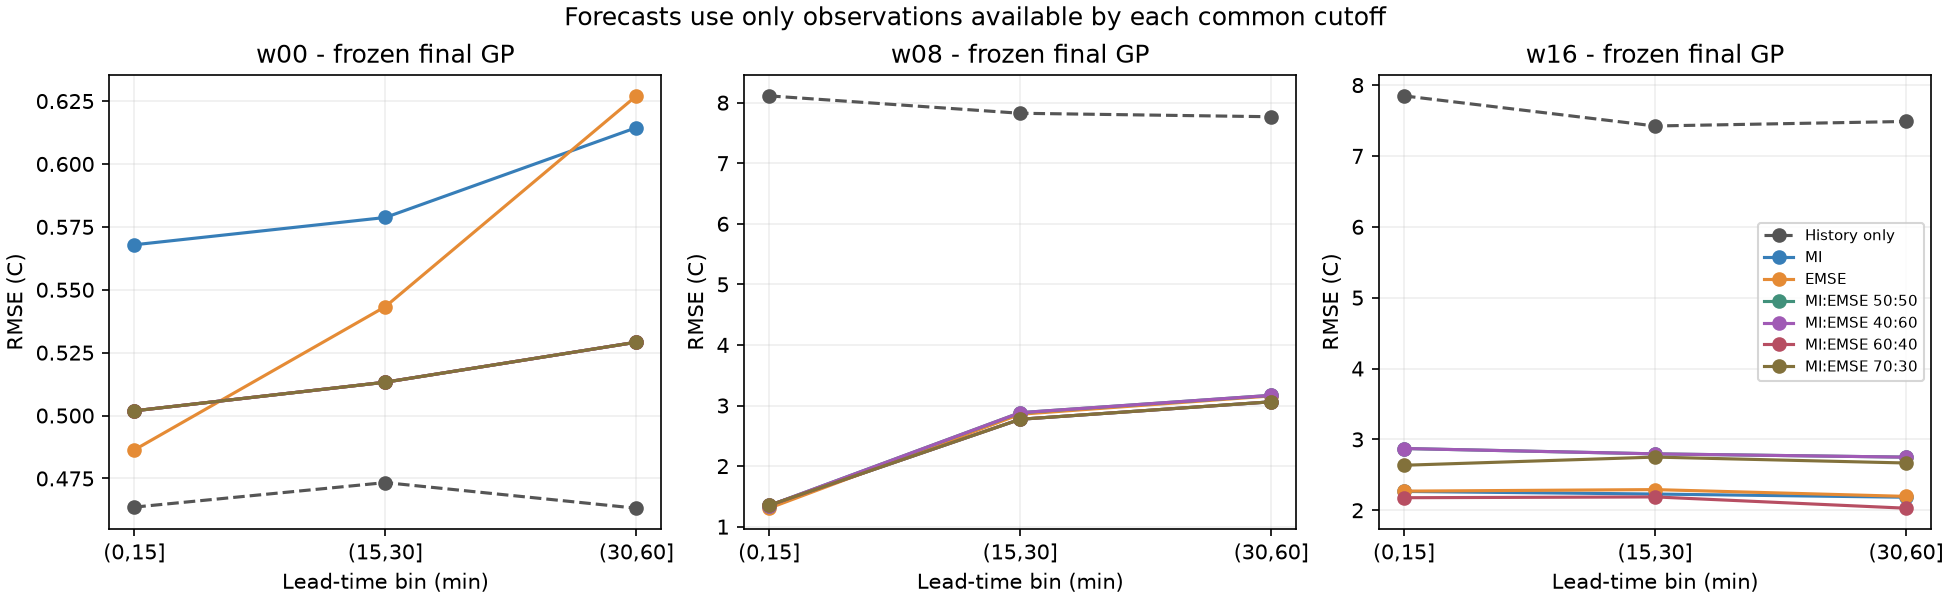

In [3]:
display(Markdown('| Window | Policy | Reconstruction RMSE | Forecast (0,15] | Forecast (15,30] | Forecast (30,60] |\n|---|---|---:|---:|---:|---:|\n| w00 | History only | 0.489578 | 0.463602 | 0.473355 | 0.463175 |\n| w00 | MI | 0.546907 | 0.567876 | 0.578728 | 0.614442 |\n| w00 | EMSE | 0.527523 | 0.486340 | 0.543291 | 0.627064 |\n| w00 | MI:EMSE 50:50 | 0.496601 | 0.501875 | 0.513260 | 0.529163 |\n| w00 | MI:EMSE 40:60 | 0.496601 | 0.501875 | 0.513260 | 0.529163 |\n| w00 | MI:EMSE 60:40 | 0.496601 | 0.501875 | 0.513260 | 0.529163 |\n| w00 | MI:EMSE 70:30 | 0.496601 | 0.501875 | 0.513260 | 0.529163 |\n| w08 | History only | 7.644961 | 8.111826 | 7.824759 | 7.767400 |\n| w08 | MI | 1.242893 | 1.351817 | 2.773157 | 3.061642 |\n| w08 | EMSE | 0.989282 | 1.305019 | 2.855750 | 3.158509 |\n| w08 | MI:EMSE 50:50 | 1.194340 | 1.348177 | 2.882170 | 3.168412 |\n| w08 | MI:EMSE 40:60 | 1.194340 | 1.348177 | 2.882170 | 3.168412 |\n| w08 | MI:EMSE 60:40 | 1.242893 | 1.351817 | 2.773157 | 3.061642 |\n| w08 | MI:EMSE 70:30 | 1.242893 | 1.351817 | 2.773157 | 3.061642 |\n| w16 | History only | 7.277005 | 7.847742 | 7.422747 | 7.486755 |\n| w16 | MI | 1.927421 | 2.265797 | 2.228827 | 2.183742 |\n| w16 | EMSE | 1.941144 | 2.269729 | 2.291498 | 2.195671 |\n| w16 | MI:EMSE 50:50 | 2.375668 | 2.871435 | 2.795814 | 2.749514 |\n| w16 | MI:EMSE 40:60 | 2.375668 | 2.871435 | 2.795814 | 2.749514 |\n| w16 | MI:EMSE 60:40 | 1.911620 | 2.176834 | 2.188111 | 2.028881 |\n| w16 | MI:EMSE 70:30 | 2.396200 | 2.634816 | 2.750152 | 2.666887 |'))
display(Image(filename=str(run/'figures/forecast_by_window.png')))

## All six sampling routes at w00

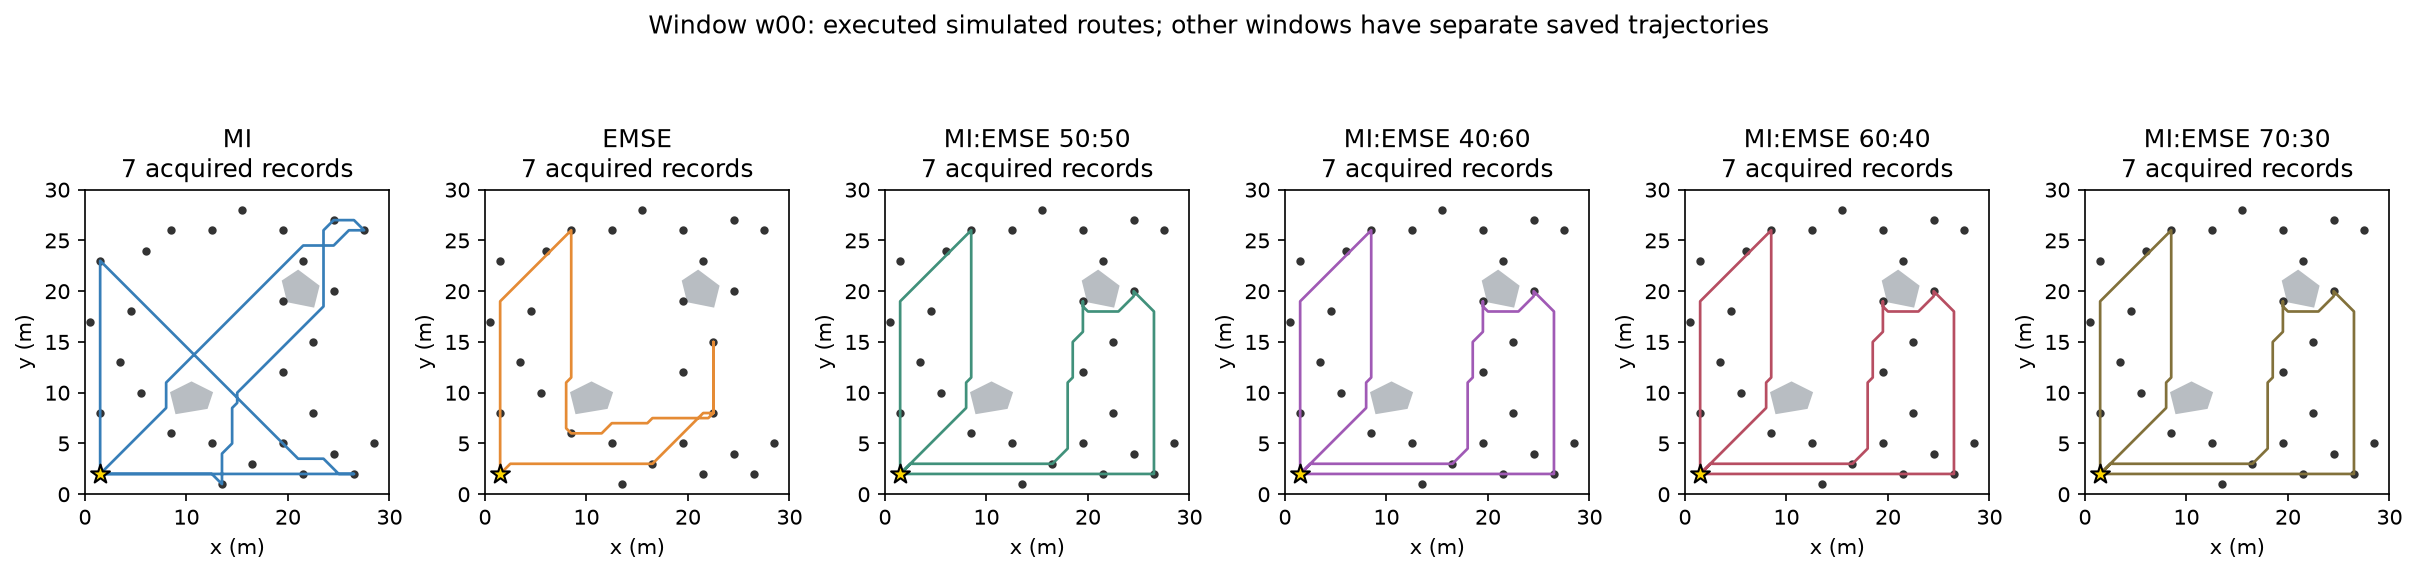

In [4]:
display(Image(filename=str(run/'figures/five_routes_w00.png')))

## Independently recompute all saved empirical RMSEs

In [5]:
verified=0
for metric in read(run/'evaluation.json'):
    folder=run/'windows'/metric['window']/metric['policy']
    with (folder/(metric['task']+'_predictions.csv')).open() as stream:
        rows=list(csv.DictReader(stream))
    error=np.array([float(r['predicted_temperature_c'])-float(r['temperature_c']) for r in rows])
    assert np.isclose(np.sqrt(np.mean(error**2)),metric['rmse_c'],atol=1e-10)
    if metric['task'].startswith('forecast'):
        lo,hi=[int(v.rstrip('m')) for v in metric['task'].split('_')[1:]]
        origin=metric['forecast_origin_h']
        assert all(origin+lo/60<float(r['t_h'])<=origin+hi/60 for r in rows)
    verified+=1
print('Verified task/model/window results:',verified)

Verified task/model/window results: 84


## Interpretation limits

These are descriptive comparisons on the same three previously inspected windows. Do not present the added ratio as independently validated or universally best. The stored data support recorded-location reconstruction and strictly future forecasting, not dense spatial ground truth or real-robot execution.